# Option Contract Analysis - ETH + BTC

You are an **option buyer**. This notebook inspects every liquid contract and produces one clear BUY recommendation.

**Data:** Deribit public API. No DB, no files, no keys.

**Output:** One BUY contract, one alternative, and a full regime summary.

## Setup

If this fails, run:

```
pip install requests pandas numpy matplotlib scipy
```

In [37]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (12, 4)

DERIBIT     = 'https://www.deribit.com/api/v2/public'
UNDERLYINGS = ['ETH', 'BTC']
print('ready')

ready


## 1. Fetch the live chain

One call per currency returns every option contract.

In [38]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=30)
    r.raise_for_status()
    return r.json()['result']

def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None

In [39]:
frames = []
for cur in UNDERLYINGS:
    print(f'fetching {cur}...')
    raw = fetch_chain(cur)
    now_ms = int(time.time() * 1000)
    rows = []
    for r in raw:
        p = parse_name(r['instrument_name'])
        if p is None:
            continue
        rows.append({
            'underlying': cur, 'expiry': p[0], 'strike': p[1], 'kind': p[2],
            'ts': now_ms,
            'mark': r.get('mark_price'), 'bid': r.get('bid_price'), 'ask': r.get('ask_price'),
            'iv': r.get('mark_iv'), 'oi': r.get('open_interest'), 'volume': r.get('volume'),
            'underlying_price': r.get('underlying_price'),
        })
    df_cur = pd.DataFrame(rows)
    print(f'  {len(df_cur)} contracts')
    frames.append(df_cur)
    time.sleep(0.4)

df = pd.concat(frames, ignore_index=True)
df['iv_dec'] = df['iv'] / 100.0
df['days']   = (df['expiry'] - df['ts']) / 86_400_000
print(f'\ntotal: {len(df)} rows')
df.head()

fetching ETH...


  722 contracts
fetching BTC...
  872 contracts

total: 1594 rows


,underlying,expiry,strike,kind,ts,mark,bid,ask,iv,oi,volume,underlying_price,iv_dec,days
0,ETH,1795766400000,3100.0,P,1793090259828,0.342273,0.3380,0.3475,56.88,19.0,0.0,2314.75,0.5688,30.973845
1,ETH,1821772800000,2300.0,P,1793090259828,0.175890,0.1745,0.1775,53.74,2145.0,2000.0,2408.71,0.5374,331.973845
2,ETH,1794556800000,2200.0,P,1793090259828,0.024267,0.0240,0.0245,52.77,669.0,60.0,2311.51,0.5277,16.973845
3,ETH,1813910400000,2900.0,P,1793090259828,0.317864,0.3160,0.3210,53.00,508.0,0.0,2379.21,0.5300,240.973845
4,ETH,1793347200000,2150.0,C,1793090259828,0.071656,0.0695,0.0725,63.78,1038.0,0.0,2308.80,0.6378,2.973845


## 2. Contract inventory

In [40]:
inv = df.groupby('underlying').agg(
    contracts=('strike', 'count'),
    expiries=('expiry', 'nunique'),
    strikes=('strike', 'nunique'),
    calls=('kind', lambda s: (s == 'C').sum()),
    puts=('kind',  lambda s: (s == 'P').sum()),
)
inv

,contracts,expiries,strikes,calls,puts
underlying,,,,,
BTC,872,11,89,436,436
ETH,722,11,84,361,361


## 3. Spot price

In [41]:
spots = {}
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    if s.empty:
        continue
    valid = s[s.underlying_price.notna()]
    if len(valid):
        spots[cur] = float(valid.underlying_price.iloc[0])
    else:
        near = s[s.expiry == s.expiry.min()]
        spots[cur] = float(near.strike.median())

for k, v in spots.items():
    print(f'{k} spot = {v:.2f}')

ETH spot = 2314.75
BTC spot = 79712.42


## 4. Expiry distribution

How many contracts per expiry. Expiries far out have less liquidity.

In [42]:
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    by_exp = s.groupby('expiry').agg(
        contracts=('strike', 'count'),
        days=('days', 'first'),
        oi_total=('oi', 'sum'),
    ).reset_index()
    by_exp['expiry_str'] = pd.to_datetime(by_exp.expiry, unit='ms').dt.strftime('%Y-%m-%d')
    by_exp = by_exp.sort_values('expiry').head(10)
    print(f'\n--- {cur} next 10 expiries ---')
    print(by_exp[['expiry_str', 'days', 'contracts', 'oi_total']].to_string(index=False))


--- ETH next 10 expiries ---
expiry_str       days  contracts  oi_total
2026-10-28   0.973845         60   11725.0
2026-10-29   1.973845         54   12151.0
2026-10-30   2.973845         96  328442.0
2026-10-31   3.973845         44    1000.0
2026-11-06   9.973845         30   36107.0
2026-11-13  16.973845         30    9877.0
2026-11-27  30.973845         72  158614.0
2026-12-25  58.973845         88  616287.0
2027-03-26 149.973845         84  217999.0
2027-06-25 240.973845         86   85769.0

--- BTC next 10 expiries ---
expiry_str       days  contracts  oi_total
2026-10-28   0.973834         54    3243.0
2026-10-29   1.973834         54    1275.5
2026-10-30   2.973834        124  135425.0
2026-10-31   3.973834         50       0.0
2026-11-06   9.973834         44   13333.1
2026-11-13  16.973834         34    1466.6
2026-11-27  30.973834         96   39468.9
2026-12-25  58.973834        118  135264.9
2027-03-26 149.973834        104   43191.8
2027-06-25 240.973834        108   14

## 5. Put/Call ratio

PCR > 1.2 = fear. PCR < 0.7 = greed.

In [43]:
def pcr_meaning(ratio, pcr_type='oi'):
    """Interpret a Put/Call ratio for an option buyer."""
    if ratio > 2.0:
        return "EXTREME FEAR - contrarian: calls very cheap, strong buy signal"
    if ratio > 1.5:
        return "HIGH FEAR - contrarian: favor CALLS"
    if ratio > 1.15:
        return "moderate fear - slight edge for CALLS"
    if ratio > 0.85:
        return "BALANCED - no directional edge from PCR"
    if ratio > 0.65:
        return "moderate greed - slight edge for PUTS"
    if ratio > 0.4:
        return "HIGH GREED - contrarian: favor PUTS"
    return "EXTREME GREED - upside crowded, favor PUTS strongly"


pcr = {}
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    oic, oip = s[s.kind=='C'].oi.sum(), s[s.kind=='P'].oi.sum()
    vc,  vp  = s[s.kind=='C'].volume.sum(), s[s.kind=='P'].volume.sum()
    pcr[cur] = {'oi': float(oip/max(oic,1)), 'vol': float(vp/max(vc,1)),
                'oic': float(oic), 'oip': float(oip)}

    print(f"\n{'=' * 70}")
    print(f"{cur} PUT/CALL RATIO ANALYSIS")
    print(f"{'=' * 70}")
    print(f"  Call OI      : {oic:>12,.0f}")
    print(f"  Put OI       : {oip:>12,.0f}")
    print(f"  Call volume  : {vc:>12,.0f}")
    print(f"  Put volume   : {vp:>12,.0f}")
    print()
    print(f"  PCR (OI)     = {pcr[cur]['oi']:.2f}   <- {pcr_meaning(pcr[cur]['oi'])}")
    print(f"  PCR (volume) = {pcr[cur]['vol']:.2f}   <- {pcr_meaning(pcr[cur]['vol'])}")
    print()
    print(f"  WHAT IT MEANS:")
    ratio = pcr[cur]['oi']
    if ratio > 1.15:
        print(f"  -> {oip:,.0f} puts vs {oic:,.0f} calls. More puts than calls.")
        print(f"  -> Crowd is BUYING PROTECTION (fearful).")
        print(f"  -> Contrarian read: upside surprise more likely than downside.")
        print(f"  -> ACTION: consider CALLS, not puts.")
    elif ratio < 0.85:
        print(f"  -> {oic:,.0f} calls vs {oip:,.0f} puts. More calls than puts.")
        print(f"  -> Crowd is CHASING UPSIDE (greedy).")
        print(f"  -> Contrarian read: no more buyers left above, downside surprise more likely.")
        print(f"  -> ACTION: consider PUTS, not calls.")
    else:
        print(f"  -> Roughly balanced ({oic:,.0f} calls vs {oip:,.0f} puts).")
        print(f"  -> No contrarian edge from PCR alone.")
        print(f"  -> ACTION: use IV rank + skew to decide direction.")


ETH PUT/CALL RATIO ANALYSIS
  Call OI      :    1,006,828
  Put OI       :      499,262
  Call volume  :       26,312
  Put volume   :       25,133

  PCR (OI)     = 0.50   <- HIGH GREED - contrarian: favor PUTS
  PCR (volume) = 0.96   <- BALANCED - no directional edge from PCR

  WHAT IT MEANS:
  -> 1,006,828 calls vs 499,262 puts. More calls than puts.
  -> Crowd is CHASING UPSIDE (greedy).
  -> Contrarian read: no more buyers left above, downside surprise more likely.
  -> ACTION: consider PUTS, not calls.

BTC PUT/CALL RATIO ANALYSIS
  Call OI      :      244,757
  Put OI       :      146,773
  Call volume  :        9,839
  Put volume   :        6,346

  PCR (OI)     = 0.60   <- HIGH GREED - contrarian: favor PUTS
  PCR (volume) = 0.65   <- HIGH GREED - contrarian: favor PUTS

  WHAT IT MEANS:
  -> 244,757 calls vs 146,773 puts. More calls than puts.
  -> Crowd is CHASING UPSIDE (greedy).
  -> Contrarian read: no more buyers left above, downside surprise more likely.
  -> ACTION: 

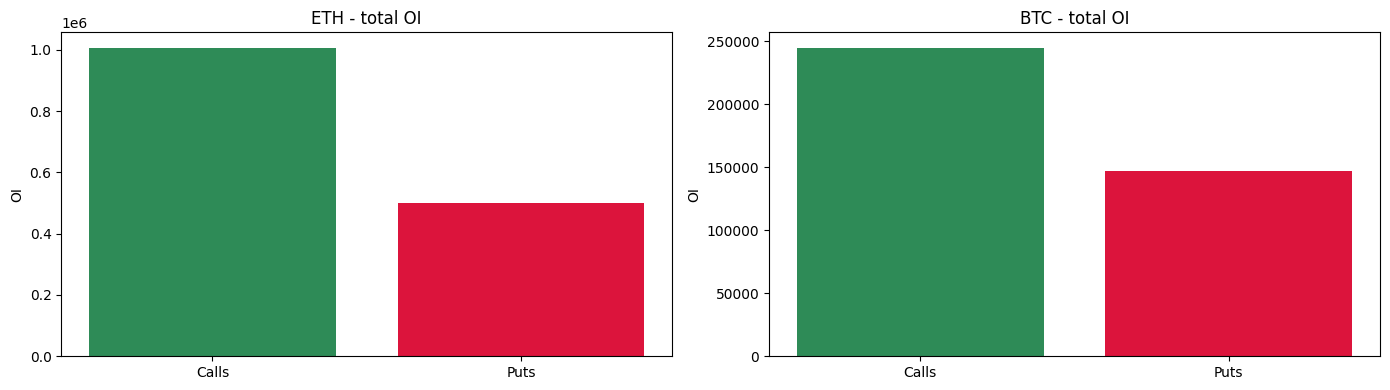

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i, cur in enumerate(UNDERLYINGS):
    if cur not in pcr: continue
    s = df[df.underlying == cur]
    oi_c = s[s.kind=='C'].oi.sum()
    oi_p = s[s.kind=='P'].oi.sum()
    axes[i].bar(['Calls','Puts'], [oi_c, oi_p], color=['seagreen','crimson'])
    axes[i].set_title(f'{cur} - total OI')
    axes[i].set_ylabel('OI')
plt.tight_layout(); plt.show()

## OI and Volume: calls vs puts (stacked bar)


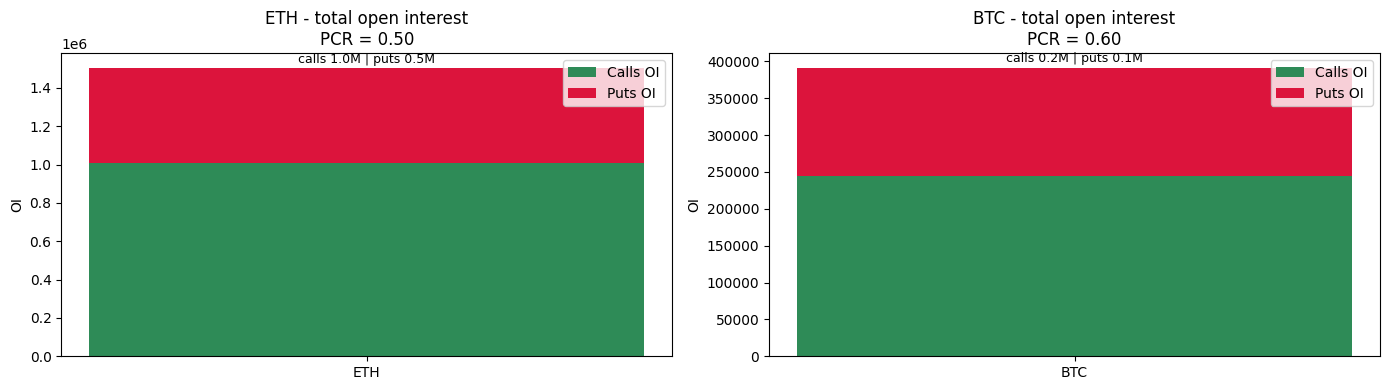

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, cur in enumerate([c for c in pcr]):
    ax = axes[i]
    calls = [pcr[cur]['oic']]
    puts  = [pcr[cur]['oip']]
    x = [cur]
    ax.bar(x, calls, color='seagreen', label='Calls OI', width=0.4)
    ax.bar(x, puts,  color='crimson',  label='Puts OI', bottom=calls, width=0.4)
    ax.set_title(f'{cur} - total open interest\nPCR = {pcr[cur]["oi"]:.2f}')
    ax.set_ylabel('OI')
    ax.legend()
    # annotate the ratio
    ax.text(0, pcr[cur]['oic'] + pcr[cur]['oip'] * 1.05,
            f'calls {pcr[cur]["oic"]/1e6:.1f}M | puts {pcr[cur]["oip"]/1e6:.1f}M',
            ha='center', fontsize=9)

plt.tight_layout(); plt.show()

### PCR gauge (dial with zones)


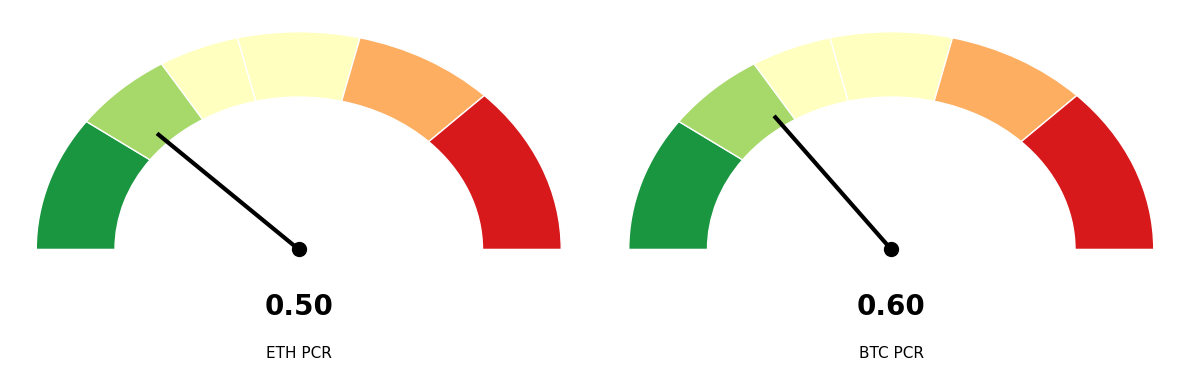

In [46]:
def draw_pcr_gauge(ax, ratio, title):
    """Semicircular gauge, 0 to 2.0 scale, green (greed) -> red (fear)."""
    # background bands
    zones = [
        (0.0, 0.4,  '#1a9641', 'EXTREME GREED'),
        (0.4, 0.65, '#a6d96a', 'HIGH GREED'),
        (0.65, 0.85,'#ffffbf', 'moderate greed'),
        (0.85, 1.15,'#ffffbf', 'BALANCED'),
        (1.15, 1.5, '#fdae61', 'moderate fear'),
        (1.5, 2.0,  '#d7191c', 'HIGH FEAR'),
    ]
    for lo, hi, color, _ in zones:
        theta1 = 180 - (hi / 2.0) * 180
        theta2 = 180 - (lo / 2.0) * 180
        ax.add_patch(plt.matplotlib.patches.Wedge(
            (0, 0), 1, theta1, theta2, width=0.3, facecolor=color, edgecolor='white'))
    # needle
    theta = np.pi * (1 - ratio / 2.0)
    ax.plot([0, np.cos(theta) * 0.75], [0, np.sin(theta) * 0.75], 'k-', lw=3)
    ax.plot(0, 0, 'ko', ms=10)
    ax.text(0, -0.3, f'{ratio:.2f}', ha='center', fontsize=20, fontweight='bold')
    ax.text(0, -0.5, title, ha='center', fontsize=11)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-0.6, 1.1)
    ax.axis('off')

fig, axes = plt.subplots(1, len(pcr), figsize=(6 * len(pcr), 4))
if len(pcr) == 1: axes = [axes]
for ax, cur in zip(axes, pcr):
    draw_pcr_gauge(ax, pcr[cur]['oi'], f'{cur} PCR')
plt.tight_layout(); plt.show()

### Per-expiry PCR (the important one)

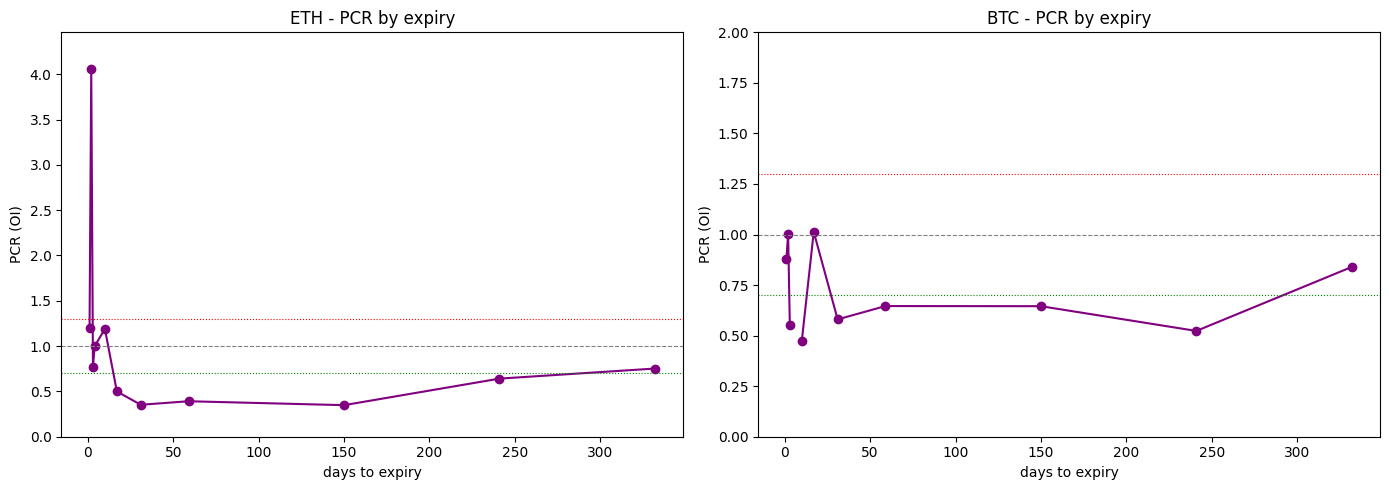

In [47]:
fig, axes = plt.subplots(1, len(UNDERLYINGS), figsize=(14, 5))
if len(UNDERLYINGS) == 1: axes = [axes]

for ax, cur in zip(axes, UNDERLYINGS):
    s = df[df.underlying == cur]
    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp[by_exp.days > 0].sort_values('days')
    by_exp['pcr'] = by_exp['P'] / by_exp['C'].replace(0, np.nan)

    ax.plot(by_exp.days, by_exp.pcr, marker='o', lw=1.5, color='purple')
    ax.axhline(1.0, ls='--', color='gray', lw=0.8)
    ax.axhline(0.7, ls=':', color='green', lw=0.8)
    ax.axhline(1.3, ls=':', color='red', lw=0.8)
    ax.set_title(f'{cur} - PCR by expiry')
    ax.set_xlabel('days to expiry')
    ax.set_ylabel('PCR (OI)')
    ax.set_ylim(0, max(2.0, by_exp.pcr.max() * 1.1))

plt.tight_layout(); plt.show()

Strike-level OI showing put wall vs call wall


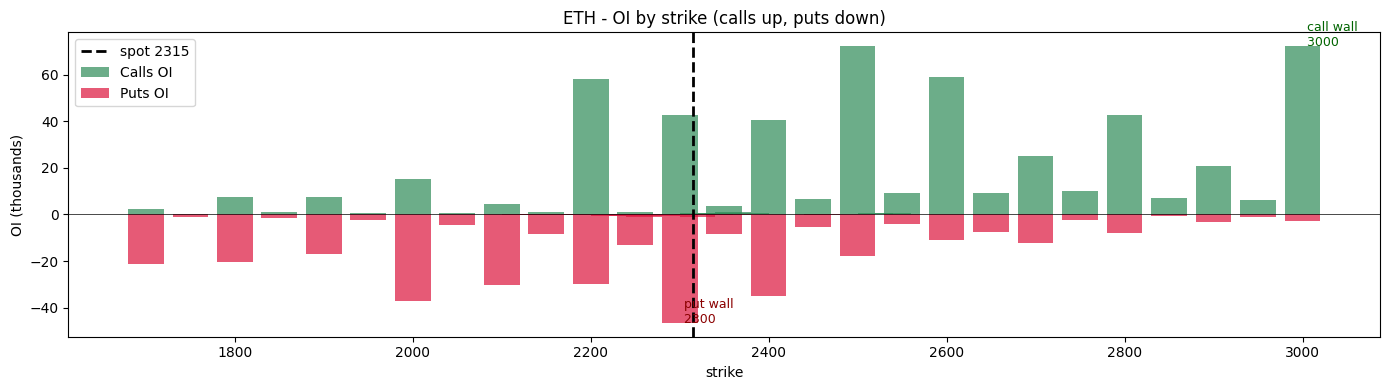

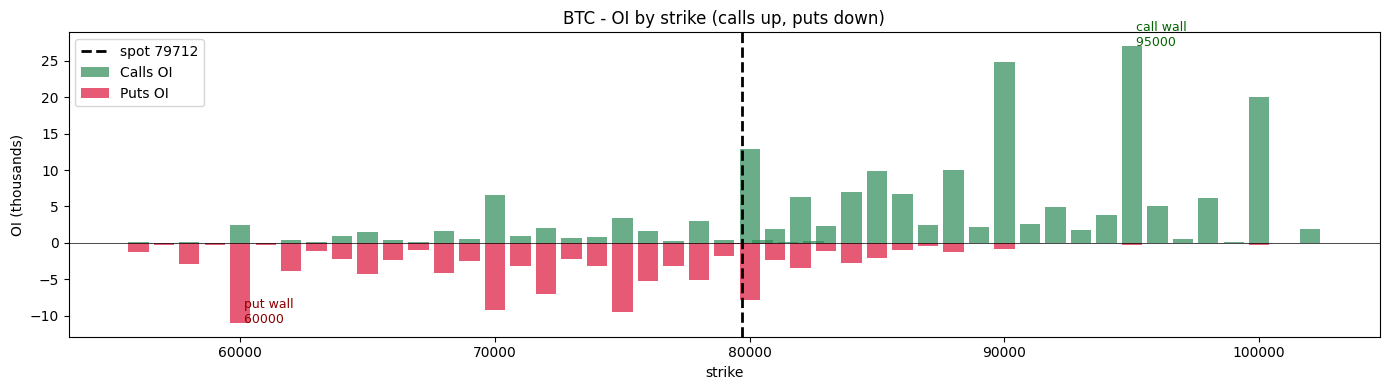

In [48]:
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    # limit to strikes near spot
    near = s[(s.strike > spots[cur] * 0.7) & (s.strike < spots[cur] * 1.3)]
    pivot = near.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)

    fig, ax = plt.subplots(figsize=(14, 4))
    x = pivot.index
    ax.bar(x, pivot['C'] / 1e3, color='seagreen', alpha=0.7, label='Calls OI', width=(x[1]-x[0])*0.8)
    ax.bar(x, -pivot['P'] / 1e3, color='crimson', alpha=0.7, label='Puts OI', width=(x[1]-x[0])*0.8)
    ax.axvline(spots[cur], color='black', lw=2, ls='--', label=f'spot {spots[cur]:.0f}')
    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'{cur} - OI by strike (calls up, puts down)')
    ax.set_xlabel('strike')
    ax.set_ylabel('OI (thousands)')
    ax.legend()

    # annotate max OI strikes
    call_wall = pivot['C'].idxmax()
    put_wall  = pivot['P'].idxmax()
    ax.text(call_wall, pivot['C'].max() / 1e3, f' call wall\n {call_wall:.0f}',
            color='darkgreen', fontsize=9)
    ax.text(put_wall, -pivot['P'].max() / 1e3, f' put wall\n {put_wall:.0f}',
            color='darkred', fontsize=9)

    plt.tight_layout(); plt.show()

PCR by hour of day (are people buying protection when?)


In [49]:
for cur in UNDERLYINGS:
    s = df[df.underlying == cur].copy()
    # use trade volume field — Deribit doesn't give hourly, so we use latest snapshot
    print(f'\n{cur}: hourly PCR requires historical snapshots.')
    print(f'  Current snapshot only - rerun daily to build history.')
    print(f'  Today: PCR(OI)={pcr[cur]["oi"]:.2f}   PCR(vol)={pcr[cur]["vol"]:.2f}')


ETH: hourly PCR requires historical snapshots.
  Current snapshot only - rerun daily to build history.
  Today: PCR(OI)=0.50   PCR(vol)=0.96

BTC: hourly PCR requires historical snapshots.
  Current snapshot only - rerun daily to build history.
  Today: PCR(OI)=0.60   PCR(vol)=0.65


PCR comparison heatmap (all expiries × call/put OI)


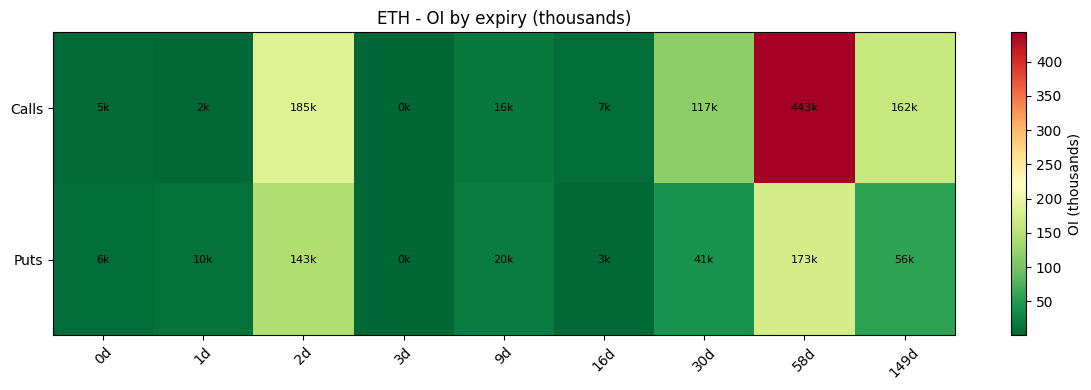

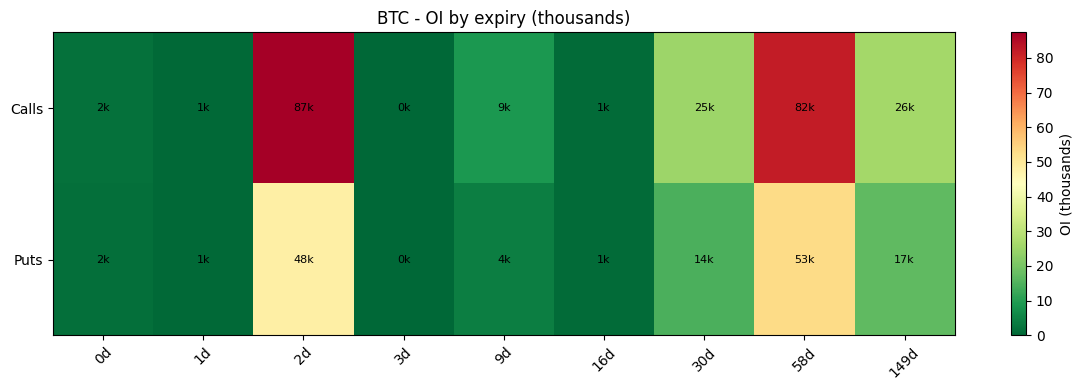

In [50]:
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    by_exp = s.groupby(['expiry', 'kind']).oi.sum().unstack('kind').fillna(0)
    by_exp['days'] = (by_exp.index - int(time.time() * 1000)) / 86_400_000
    by_exp = by_exp[(by_exp.days > 0) & (by_exp.days < 180)].sort_values('days')

    fig, ax = plt.subplots(figsize=(12, 4))
    data = by_exp[['C', 'P']].T.values / 1e3  # thousands
    im = ax.imshow(data, aspect='auto', cmap='RdYlGn_r')
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Calls', 'Puts'])
    ax.set_xticks(range(len(by_exp)))
    ax.set_xticklabels([f'{int(d)}d' for d in by_exp.days], rotation=45)
    for i in range(2):
        for j in range(len(by_exp)):
            ax.text(j, i, f'{data[i, j]:.0f}k', ha='center', va='center', fontsize=8)
    ax.set_title(f'{cur} - OI by expiry (thousands)')
    plt.colorbar(im, ax=ax, label='OI (thousands)')
    plt.tight_layout(); plt.show()

Buyer's decision matrix (the summary figure)

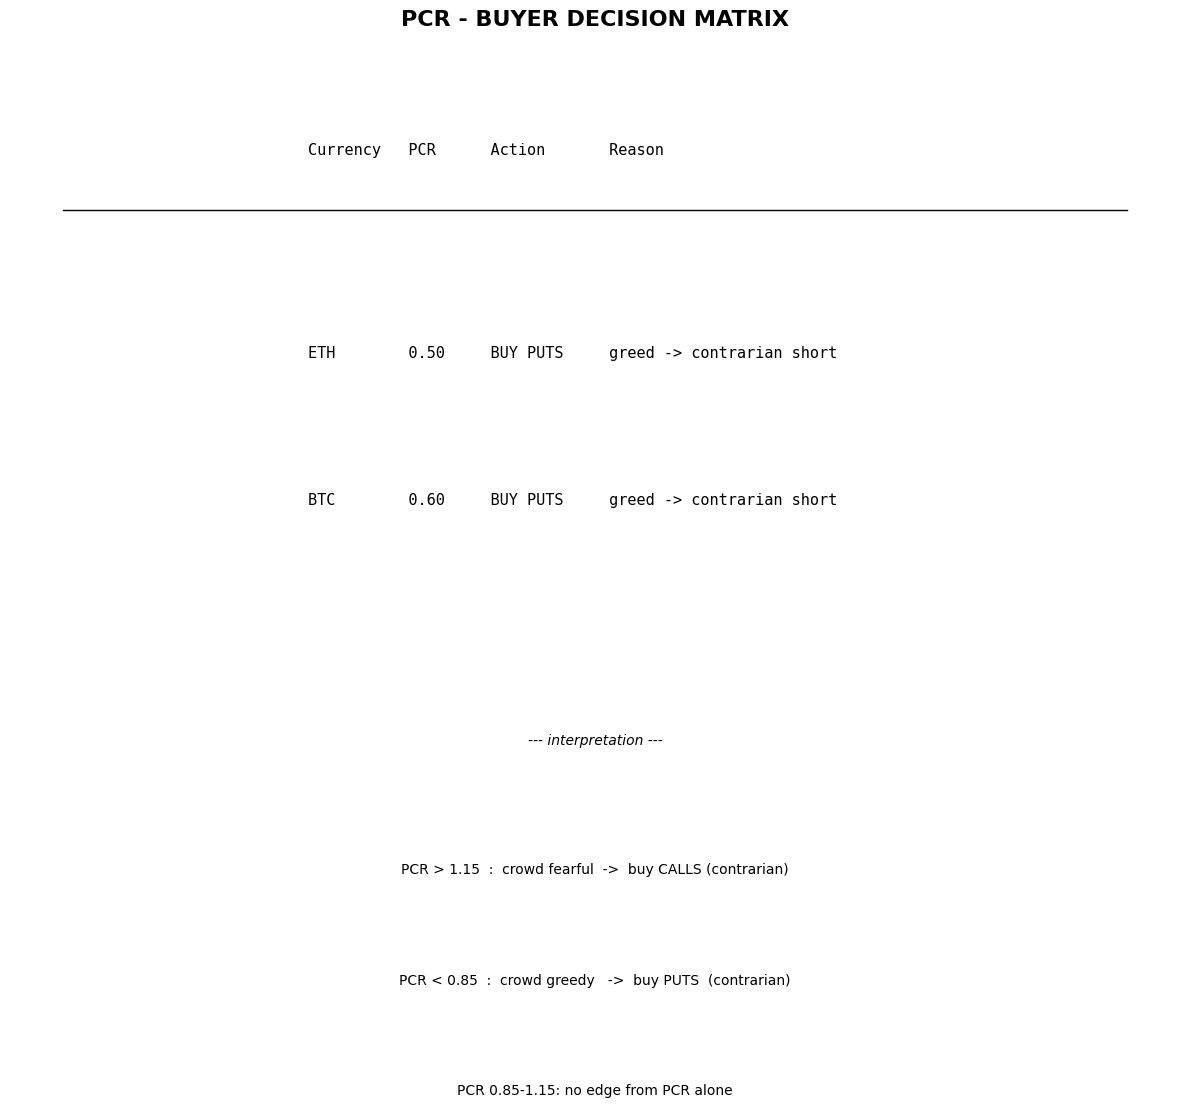

In [51]:
fig, ax = plt.subplots(figsize=(12, 2))
ax.axis('off')

cur_summary = []
for cur in pcr:
    oi_r = pcr[cur]['oi']
    if oi_r > 1.15:
        action = 'BUY CALLS'
        color = 'green'
        reason = 'fear -> contrarian long'
    elif oi_r < 0.85:
        action = 'BUY PUTS'
        color = 'red'
        reason = 'greed -> contrarian short'
    else:
        action = 'WAIT'
        color = 'orange'
        reason = 'balanced, no edge'
    cur_summary.append((cur, oi_r, action, color, reason))

header = f"{'Currency':<10} {'PCR':<8} {'Action':<12} {'Reason':<30}"
ax.text(0.5, 0.92, 'PCR - BUYER DECISION MATRIX', ha='center', fontsize=16, fontweight='bold')
ax.text(0.5, 0.85, header, ha='center', fontsize=11, family='monospace')
ax.plot([0.05, 0.95], [0.82, 0.82], color='black', lw=1)

y = 0.74
for cur, ratio, action, color, reason in cur_summary:
    line = f"{cur:<10} {ratio:<8.2f} {action:<12} {reason:<30}"
    ax.text(0.5, y, line, ha='center', fontsize=11, family='monospace')
    # color the action
    x_act = 0.5 + (-0.22 + 0.22 * 8/10)  # approximate position of action column
    y -= 0.08

# interpretation guide
ax.text(0.5, y - 0.05, '--- interpretation ---', ha='center', fontsize=10, style='italic')
ax.text(0.5, y - 0.12, 'PCR > 1.15  :  crowd fearful  ->  buy CALLS (contrarian)', ha='center', fontsize=10)
ax.text(0.5, y - 0.18, 'PCR < 0.85  :  crowd greedy   ->  buy PUTS  (contrarian)', ha='center', fontsize=10)
ax.text(0.5, y - 0.24, 'PCR 0.85-1.15: no edge from PCR alone', ha='center', fontsize=10)

plt.tight_layout(); plt.show()

## 6. Implied volatility stats

In [52]:
for cur in UNDERLYINGS:
    s = df[(df.underlying == cur) & df.iv_dec.notna()]
    print(f"{cur}: min={s.iv_dec.min()*100:.1f}%  "
          f"median={s.iv_dec.median()*100:.1f}%  "
          f"max={s.iv_dec.max()*100:.1f}%  "
          f"spread={((s.iv_dec.max()-s.iv_dec.min())*100):.1f}%")

ETH: min=44.0%  median=56.0%  max=149.6%  spread=105.6%
BTC: min=29.8%  median=40.2%  max=123.4%  spread=93.6%


## 7. IV smile (calls)

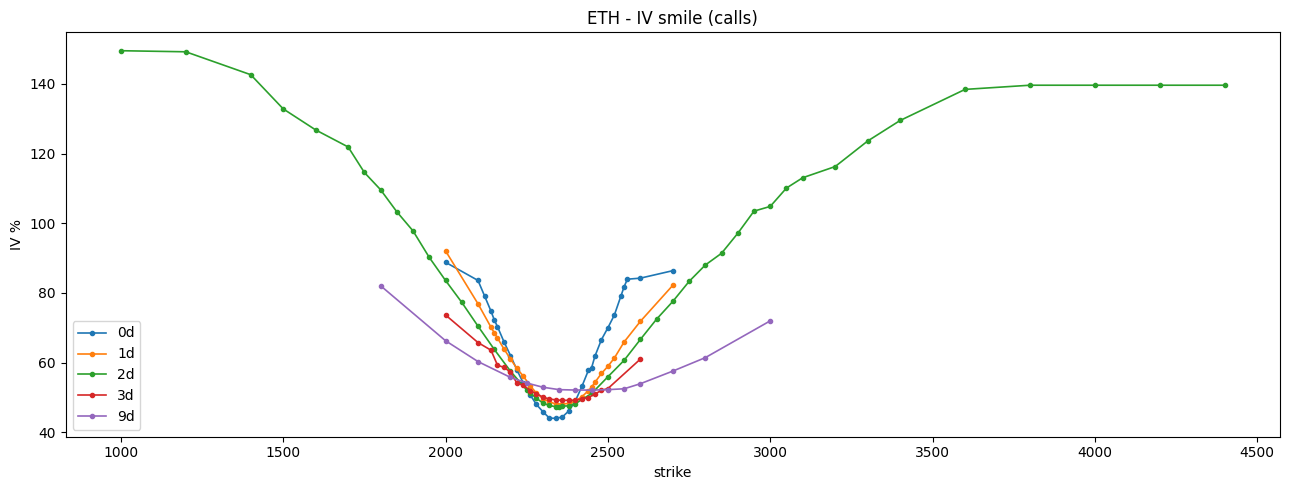

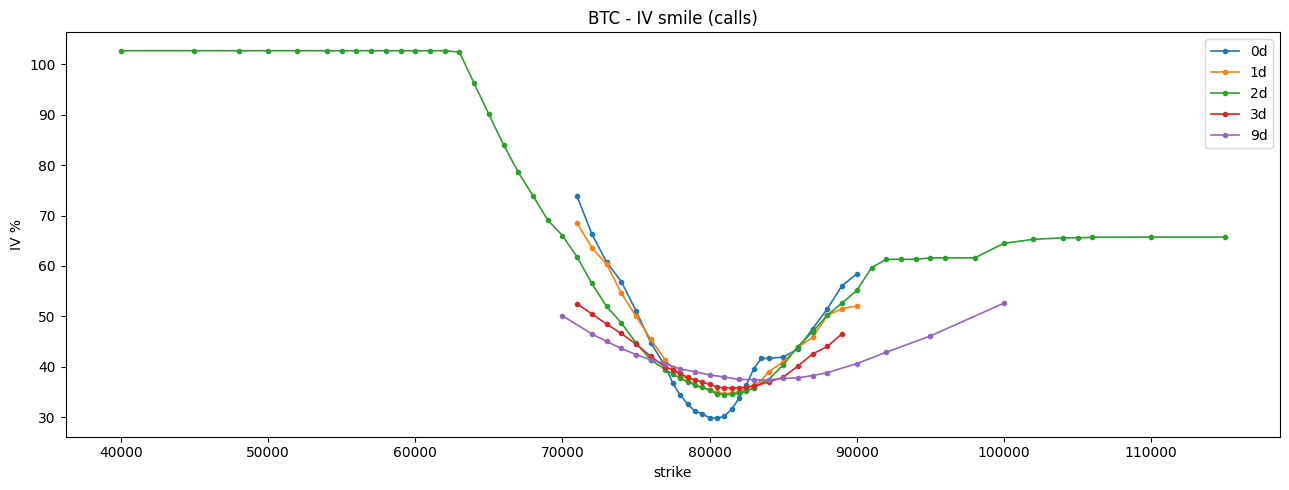

In [53]:
for cur in UNDERLYINGS:
    sub = df[df.underlying == cur]
    exps = sorted(sub.expiry.unique())[:5]
    plt.figure(figsize=(13, 5))
    for e in exps:
        s = sub[(sub.expiry == e) & (sub.kind == 'C') & sub.iv_dec.notna()].sort_values('strike')
        if len(s):
            plt.plot(s.strike, s.iv_dec * 100, marker='o', ms=3, lw=1.2,
                     label=f'{int(s.days.iloc[0])}d')
    plt.title(f'{cur} - IV smile (calls)')
    plt.xlabel('strike'); plt.ylabel('IV %'); plt.legend()
    plt.tight_layout(); plt.show()

## 8. IV smile (puts)

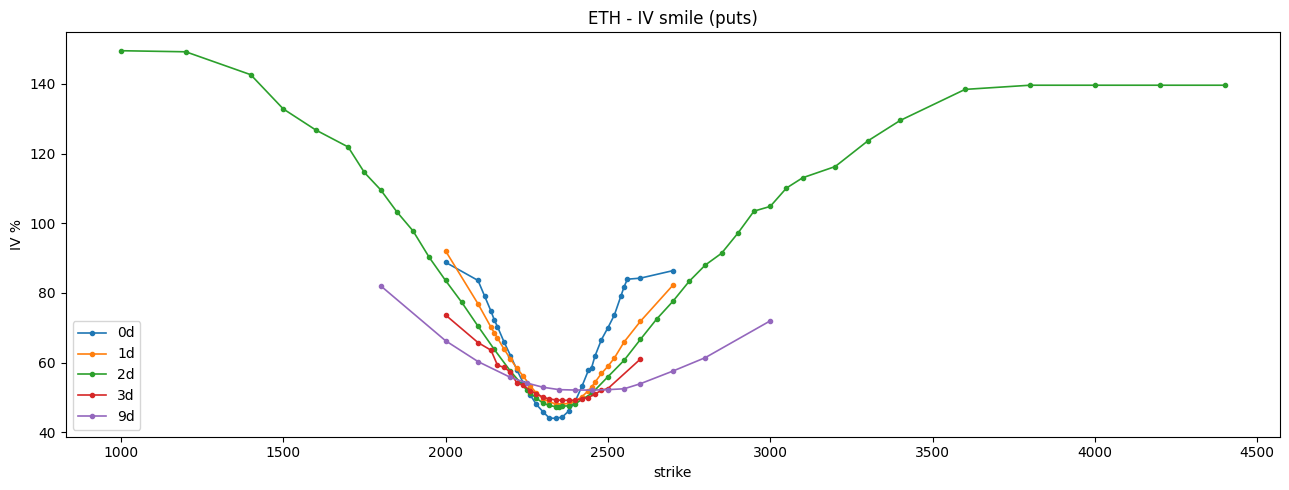

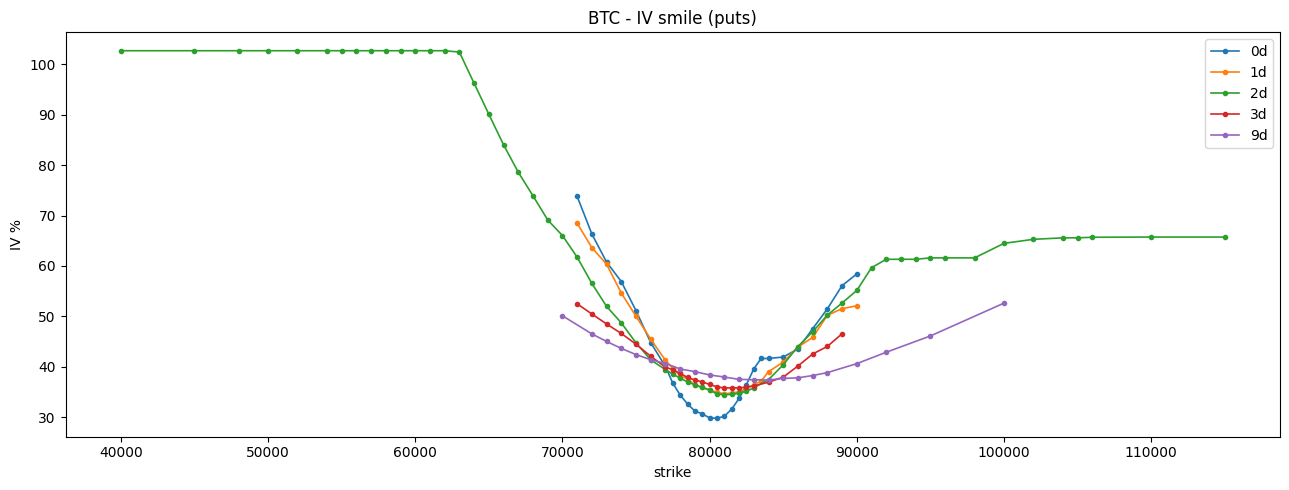

In [54]:
for cur in UNDERLYINGS:
    sub = df[df.underlying == cur]
    exps = sorted(sub.expiry.unique())[:5]
    plt.figure(figsize=(13, 5))
    for e in exps:
        s = sub[(sub.expiry == e) & (sub.kind == 'P') & sub.iv_dec.notna()].sort_values('strike')
        if len(s):
            plt.plot(s.strike, s.iv_dec * 100, marker='o', ms=3, lw=1.2,
                     label=f'{int(s.days.iloc[0])}d')
    plt.title(f'{cur} - IV smile (puts)')
    plt.xlabel('strike'); plt.ylabel('IV %'); plt.legend()
    plt.tight_layout(); plt.show()

## 9. ATM IV term structure

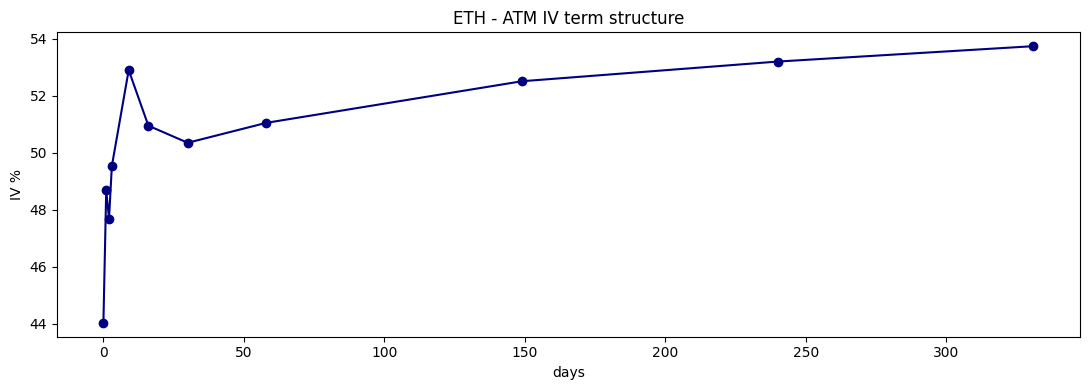

ETH: 11 expiries, IV range 44.0% - 53.7%


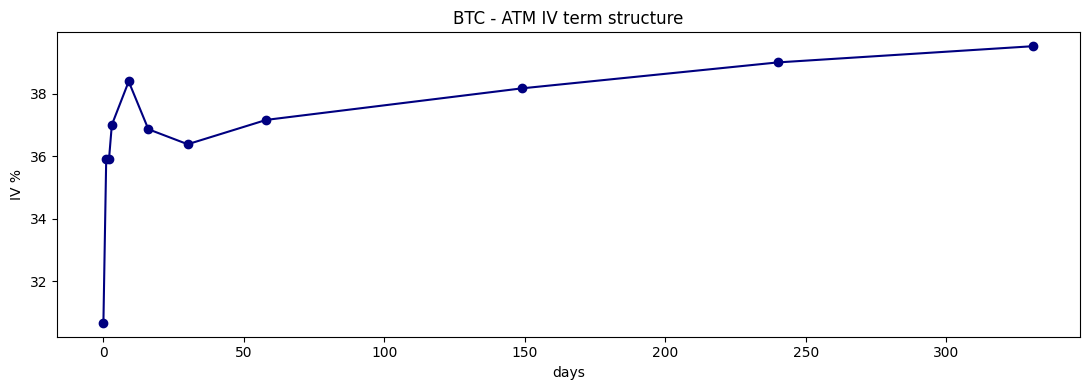

BTC: 11 expiries, IV range 30.7% - 39.5%


In [55]:
term = {}
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    spot = spots[cur]
    rows = []
    for e, g in s.groupby('expiry'):
        atm = g.iloc[(g.strike - spot).abs().argsort()[:1]]
        if len(atm) and pd.notna(atm.iv_dec.iloc[0]):
            rows.append({'days': int(atm.days.iloc[0]),
                         'atm_iv': float(atm.iv_dec.iloc[0]) * 100})
    ts = pd.DataFrame(rows).sort_values('days')
    term[cur] = ts
    plt.figure(figsize=(11, 4))
    plt.plot(ts.days, ts.atm_iv, marker='o', color='navy')
    plt.title(f'{cur} - ATM IV term structure')
    plt.xlabel('days'); plt.ylabel('IV %')
    plt.tight_layout(); plt.show()
    print(f'{cur}: {len(ts)} expiries, IV range {ts.atm_iv.min():.1f}% - {ts.atm_iv.max():.1f}%')

## 10. Compute Greeks for every contract

In [56]:
def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega  = S * pdf * np.sqrt(T) / 100
    theta = -(S * pdf * sigma) / (2 * np.sqrt(T)) / 365
    if kind == 'C':
        price = S*norm.cdf(d1) - K*norm.cdf(d2)
    else:
        price = K*norm.cdf(-d2) - S*norm.cdf(-d1)
    return {'delta': float(delta), 'gamma': float(gamma),
            'vega': float(vega), 'theta': float(theta),
            'bs_price': float(price)}

In [57]:
enriched = []
for cur in UNDERLYINGS:
    sub = df[(df.underlying == cur) & df.iv_dec.notna() & df.days.between(1, 120)]
    for _, r in sub.iterrows():
        g = bs_greeks(spots[cur], r.strike, r.days/365, r.iv_dec, r.kind)
        if g:
            enriched.append({**r.to_dict(), **g})

ek = pd.DataFrame(enriched)
print(f'enriched: {len(ek)} contracts with Greeks')
ek[['underlying','strike','kind','days','iv_dec','delta','gamma','vega','theta','mark']].head(10)

enriched: 934 contracts with Greeks


,underlying,strike,kind,days,iv_dec,delta,gamma,vega,theta,mark
0,ETH,3100.0,P,30.973845,0.5688,-0.953524,0.000254,0.655948,-0.602287,0.342273
1,ETH,2200.0,P,16.973845,0.5277,-0.307237,0.001334,1.754144,-2.726730,0.024267
2,ETH,2150.0,C,2.973845,0.6378,0.905120,0.001267,0.352815,-3.783413,0.071656
3,ETH,2380.0,P,2.973845,0.4757,-0.734323,0.003300,0.685248,-5.480659,0.036997
4,ETH,2500.0,C,1.973845,0.5890,0.039560,0.000852,0.145372,-2.168971,0.000582
5,ETH,3000.0,C,9.973845,0.7197,0.016997,0.000153,0.161292,-0.581932,0.000669
6,ETH,1800.0,P,9.973845,0.8205,-0.027290,0.000200,0.240641,-0.989817,0.001544
7,ETH,2500.0,P,1.973845,0.5890,-0.960440,0.000852,0.145372,-2.168971,0.083531
8,ETH,1750.0,C,2.973845,1.1458,0.997074,0.000037,0.018690,-0.360053,0.242126
9,ETH,2350.0,C,9.973845,0.5221,0.447506,0.001980,1.513274,-3.960760,0.026763


## 11. IV rank - is premium cheap or expensive?

IV rank < 30 = CHEAP, > 60 = EXPENSIVE.

In [58]:
def iv_index(currency, days=30):
    end = int(time.time() * 1000)
    start = end - days * 86_400_000
    try:
        r = requests.get(f'{DERIBIT}/get_volatility_index_data', params={
            'currency': currency, 'start_timestamp': start,
            'end_timestamp': end, 'resolution': '1D'}, timeout=20)
        r.raise_for_status()
        return pd.Series([x[4] for x in r.json()['result']['data']])
    except Exception as e:
        print(f'  iv_index failed for {currency}: {e}')
        return pd.Series(dtype=float)

iv_stats = {}
for cur in UNDERLYINGS:
    s = iv_index(cur)
    if len(s) < 5: continue
    cur_v = float(s.iloc[-1])
    lo, hi = float(s.min()), float(s.max())
    rank = (cur_v - lo) / (hi - lo) * 100 if hi > lo else 50
    iv_stats[cur] = {'current': cur_v, 'rank': rank, 'min': lo, 'max': hi}
    print(f'{cur}: IV={cur_v:.2f}  rank={rank:.0f}/100  range=[{lo:.1f},{hi:.1f}]')

ETH: IV=53.07  rank=91/100  range=[47.5,53.6]
BTC: IV=38.17  rank=78/100  range=[34.8,39.1]


## 12. 25-delta skew

In [59]:
skew = {}
for cur in UNDERLYINGS:
    sub = ek[(ek.underlying == cur) & ek.days.between(15, 45)]
    if sub.empty: continue
    c = sub[sub.kind=='C'].sort_values('delta')
    p = sub[sub.kind=='P'].sort_values('delta')
    if c.empty or p.empty: continue
    c25 = c.iloc[(c.delta - 0.25).abs().argsort()[:1]]
    p25 = p.iloc[(p.delta + 0.25).abs().argsort()[:1]]
    sk = float(p25.iv_dec.iloc[0] - c25.iv_dec.iloc[0])
    skew[cur] = sk
    label = 'downside fear' if sk > 0.02 else ('upside chase' if sk < -0.02 else 'balanced')
    print(f'{cur}: 25d skew = {sk*100:+.2f}%  ({label})')

ETH: 25d skew = +3.21%  (downside fear)
BTC: 25d skew = +4.46%  (downside fear)


## 13. Open interest by strike (walls)

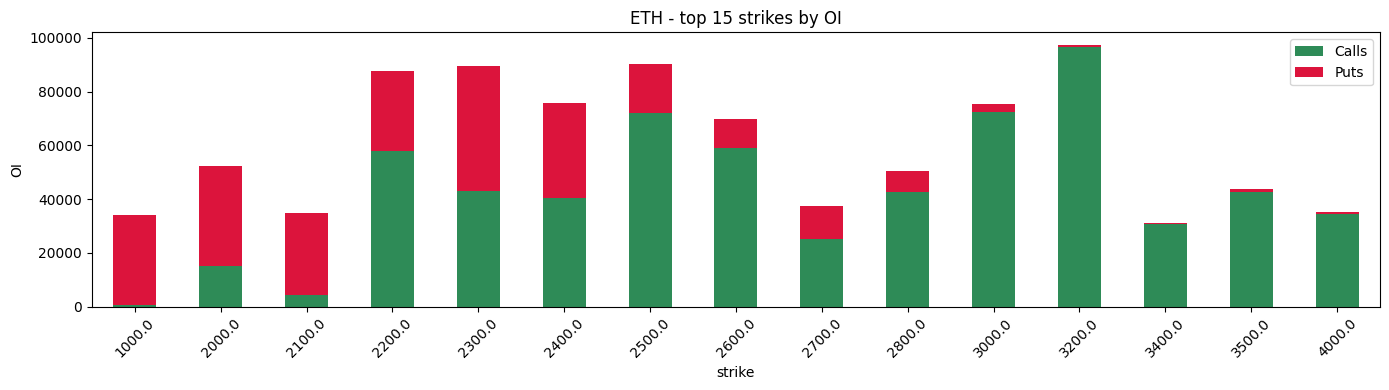

ETH: call wall @ 3200  put wall @ 2300


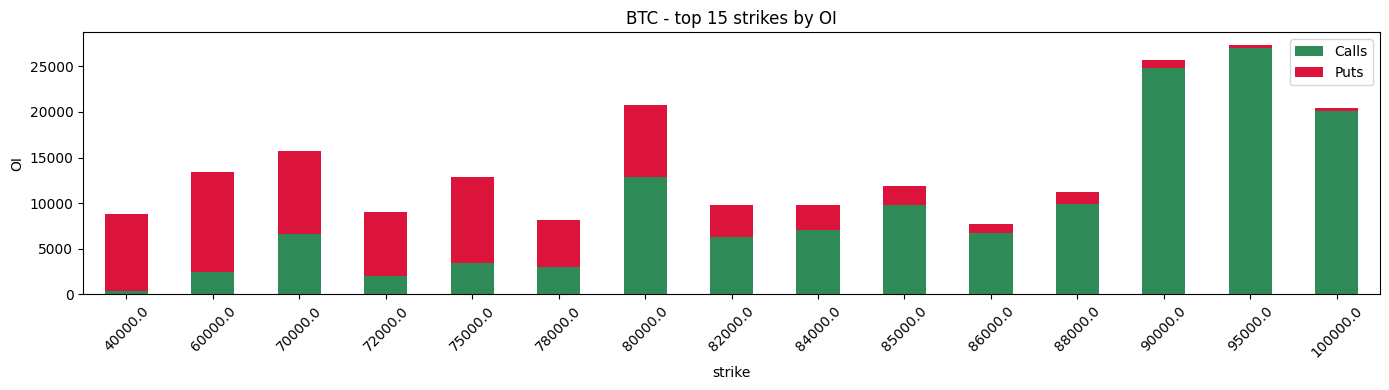

BTC: call wall @ 95000  put wall @ 60000


In [60]:
walls = {}
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    pivot = s.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)
    pivot['total'] = pivot.sum(axis=1)
    top = pivot.nlargest(15, 'total').sort_index()
    plt.figure(figsize=(14, 4))
    top[['C','P']].plot(kind='bar', stacked=True, ax=plt.gca(), color=['seagreen','crimson'])
    plt.title(f'{cur} - top 15 strikes by OI')
    plt.xlabel('strike'); plt.ylabel('OI')
    plt.xticks(rotation=45)
    plt.legend(['Calls','Puts'])
    plt.tight_layout(); plt.show()
    call_wall = float(pivot['C'].idxmax())
    put_wall  = float(pivot['P'].idxmax())
    walls[cur] = {'call': call_wall, 'put': put_wall}
    print(f'{cur}: call wall @ {call_wall:.0f}  put wall @ {put_wall:.0f}')

## 14. Top 5 strikes by OI per currency

In [61]:
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    oi = s.pivot_table(index='strike', columns='kind', values='oi', aggfunc='sum').fillna(0)
    oi['total'] = oi.sum(axis=1)
    print(f'\n{cur} top 5 strikes by total OI:')
    print(oi.nlargest(5, 'total')[['C','P','total']].to_string())


ETH top 5 strikes by total OI:
kind          C        P    total
strike                           
3200.0  96547.0    686.0  97233.0
2500.0  72249.0  18004.0  90253.0
2300.0  42896.0  46585.0  89481.0
2200.0  58057.0  29818.0  87875.0
2400.0  40469.0  35151.0  75620.0

BTC top 5 strikes by total OI:
kind            C       P    total
strike                            
95000.0   27010.2   349.5  27359.7
90000.0   24849.9   840.1  25690.0
80000.0   12875.2  7916.5  20791.7
100000.0  20059.6   345.8  20405.4
70000.0    6571.8  9189.4  15761.2


## 15. Max pain (nearest expiry)

In [62]:
def max_pain(currency):
    s = df[df.underlying == currency]
    if s.empty: return None
    sub = s[s.expiry == s.expiry.min()]
    strikes = sub.strike.unique()
    pains = {}
    for K in strikes:
        pain = 0.0
        for _, r in sub.iterrows():
            oi = r.oi or 0
            if r.kind == 'C': pain += oi * max(0.0, K - r.strike)
            else:            pain += oi * max(0.0, r.strike - K)
        pains[K] = pain
    return float(min(pains, key=pains.get))

mp = {}
for cur in UNDERLYINGS:
    m = max_pain(cur)
    if m is not None:
        mp[cur] = m
        print(f'{cur}: max pain = {m:.0f}')

ETH: max pain = 2320
BTC: max pain = 80000


## 16. ATM straddle cost - expected move

In [63]:
straddle = {}
for cur in UNDERLYINGS:
    s = df[df.underlying == cur]
    target = s[s.days.between(25, 40)]
    if target.empty: target = s[s.days.between(7, 60)]
    if target.empty: continue
    exp = target.expiry.iloc[0]
    tg = target[target.expiry == exp]
    spot = spots[cur]
    calls = tg[tg.kind=='C']
    puts  = tg[tg.kind=='P']
    if calls.empty or puts.empty: continue
    atm_c = calls.iloc[(calls.strike - spot).abs().argsort()[:1]]
    atm_p = puts.iloc[(puts.strike - spot).abs().argsort()[:1]]
    cost = float(atm_c.ask.iloc[0] or 0) + float(atm_p.ask.iloc[0] or 0)
    pct = cost / spot * 100
    straddle[cur] = {'cost': cost, 'pct': pct, 'days': int(tg.days.iloc[0])}
    print(f'{cur}: straddle={cost:.2f} ({pct:.2f}% of spot, {int(tg.days.iloc[0])}d)')

ETH: straddle=0.12 (0.01% of spot, 30d)
BTC: straddle=0.09 (0.00% of spot, 30d)


## 17. Filter to liquid candidates

In [64]:
def candidates(currency):
    s = ek[(ek.underlying == currency) & ek.days.between(7, 60)].copy()
    s = s[(s.oi > 100) & (s.volume > 0) & (s.bid > 0) & (s.ask > 0)]
    s['mid'] = (s.bid + s.ask) / 2
    s['spread'] = (s.ask - s.bid) / s['mid']
    s = s[s.spread < 0.12]
    s = s[((s.kind == 'C') & s.delta.between(0.25, 0.55))
         | ((s.kind == 'P') & s.delta.between(-0.55, -0.25))]
    return s

cand = pd.concat([candidates(c) for c in UNDERLYINGS], ignore_index=True)
print(f'candidates after filters: {len(cand)}')
cand[['underlying','strike','kind','days','iv_dec','delta','oi','volume','spread']].head(20)

candidates after filters: 67


,underlying,strike,kind,days,iv_dec,delta,oi,volume,spread
0,ETH,2200.0,P,16.973845,0.5277,-0.307237,669.0,60.0,0.020619
1,ETH,2350.0,C,9.973845,0.5221,0.447506,1493.0,483.0,0.018692
2,ETH,2400.0,C,58.973845,0.5063,0.469726,13160.0,13.0,0.014925
3,ETH,2300.0,C,30.973845,0.5035,0.546538,296.0,7.0,0.016260
4,ETH,2350.0,P,16.973845,0.5038,-0.533786,418.0,5.0,0.019048
5,ETH,2450.0,C,9.973845,0.5208,0.268761,1272.0,54.0,0.076923
6,ETH,2300.0,P,30.973845,0.5035,-0.453462,2304.0,340.0,0.018182
7,ETH,2350.0,C,16.973845,0.5038,0.466214,260.0,22.0,0.027778
8,ETH,2250.0,P,9.973845,0.5412,-0.358727,2753.0,44.0,0.041667
9,ETH,2600.0,C,58.973845,0.5056,0.319108,11046.0,2000.0,0.012903


## 18. Score every candidate

Score combines IV rank, PCR, delta fit, spread, wall distance.

In [65]:
def direction_bias(currency):
    p = pcr.get(currency, {}).get('oi', 1.0)
    if p > 1.15: return 'CALL'
    if p < 0.75: return 'PUT'
    return 'NEUTRAL'

def score_row(r):
    cur = r.underlying
    bias = direction_bias(cur)
    iv_r = iv_stats.get(cur, {}).get('rank', 50)
    pcr_oi = pcr.get(cur, {}).get('oi', 1.0)
    if bias == 'CALL':
        pf = 1.0 if pcr_oi > 1.15 else (0.5 if pcr_oi > 0.9 else 0.2)
        td = 0.40
    elif bias == 'PUT':
        pf = 1.0 if pcr_oi < 0.75 else (0.5 if pcr_oi < 1.05 else 0.2)
        td = -0.40
    else:
        pf = 0.5
        td = 0.40 if r.kind == 'C' else -0.40
    df_fit = max(0.0, 1 - abs(td - r.delta) / abs(td))
    wall = walls.get(cur, {}).get('call' if r.kind == 'C' else 'put', r.strike)
    spot = spots[cur]
    if r.kind == 'C': room = max(0.0, (wall - r.strike) / spot)
    else:             room = max(0.0, (r.strike - wall) / spot)
    wr = min(1.0, room / 0.05)
    return (0.30 * (1 - iv_r/100) + 0.25 * pf +
            0.20 * df_fit + 0.15 * (1 - min(1.0, float(r.spread))) + 0.10 * wr)

cand['score'] = [score_row(r) for r in cand.itertuples()]
cand_sorted = cand.sort_values('score', ascending=False)
print('top 5 candidates:')
print(cand_sorted[['underlying','strike','kind','days','iv_dec','delta','spread','score']].head(5).to_string(index=False))

top 5 candidates:
underlying  strike kind      days  iv_dec     delta   spread    score
       BTC 78000.0    P 30.973834  0.3718 -0.399492 0.016000 0.763625
       BTC 78000.0    P 58.973834  0.3769 -0.413288 0.021739 0.756374
       BTC 79000.0    P  9.973834  0.3905 -0.431974 0.047619 0.743149
       BTC 78000.0    P  9.973834  0.3958 -0.357693 0.030769 0.740510
       BTC 79000.0    P 30.973834  0.3676 -0.445366 0.027397 0.739487


## 19. Pick best contract per direction

In [66]:
def best_for(cur, kind):
    s = cand_sorted[(cand_sorted.underlying == cur) & (cand_sorted.kind == kind)]
    return s.iloc[0] if len(s) else None

picks = {}
for cur in UNDERLYINGS:
    bc = best_for(cur, 'C')
    bp = best_for(cur, 'P')
    if bc is not None and (bp is None or bc.score >= bp.score):
        picks[cur] = ('C', bc)
    elif bp is not None:
        picks[cur] = ('P', bp)

for cur, (k, row) in picks.items():
    print(f"{cur}: {k}  strike={row.strike:.0f}  "
          f"{int(row.days)}d  IV={row.iv_dec*100:.1f}%  delta={row.delta:.2f}  ask={row.ask:.2f}")

ETH: P  strike=2400  58d  IV=50.6%  delta=-0.53  ask=0.10
BTC: P  strike=78000  30d  IV=37.2%  delta=-0.40  ask=0.03


## 20. Greeks profile of the picked contract

In [67]:
for cur, (k, row) in picks.items():
    print(f'\n{cur} {k} delta={row.delta:.3f}  gamma={row.gamma:.5f}  '
          f'vega={row.vega:.4f}  theta={row.theta:.4f}  '
          f'bs_price={row.bs_price:.2f}  mark={row.mark:.2f}')


ETH P delta=-0.530  gamma=0.00084  vega=3.7012  theta=-1.5888  bs_price=236.69  mark=0.10

BTC P delta=-0.399  gamma=0.00004  vega=89.6819  theta=-53.8256  bs_price=2617.55  mark=0.03


## 21. Delta heatmap (strike x expiry)

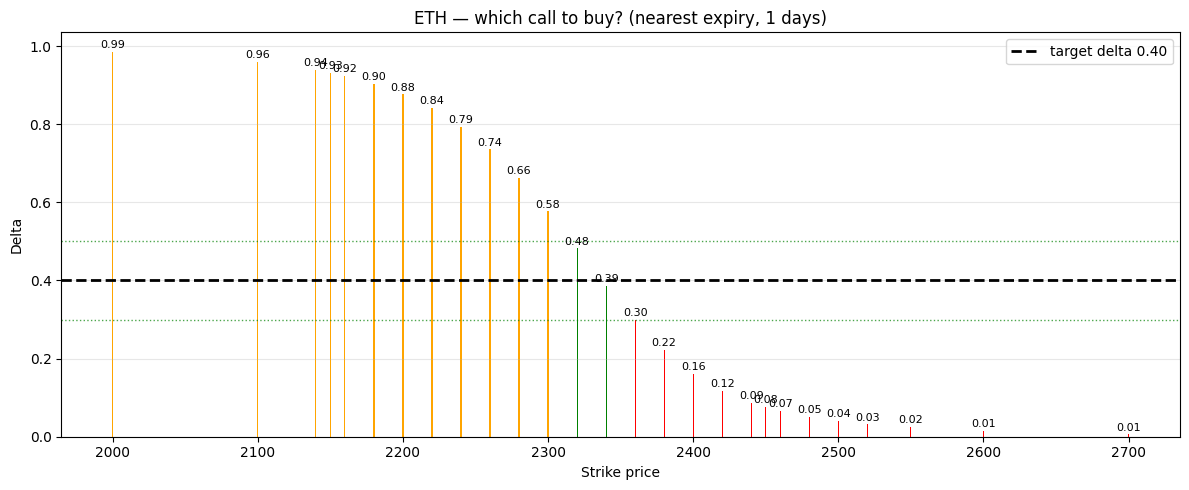


ETH - best calls to buy (delta 0.35-0.50):
  $2,320 C  delta=0.48  mark=$0.01  IV=48.7%
  $2,340 C  delta=0.39  mark=$0.01  IV=48.1%


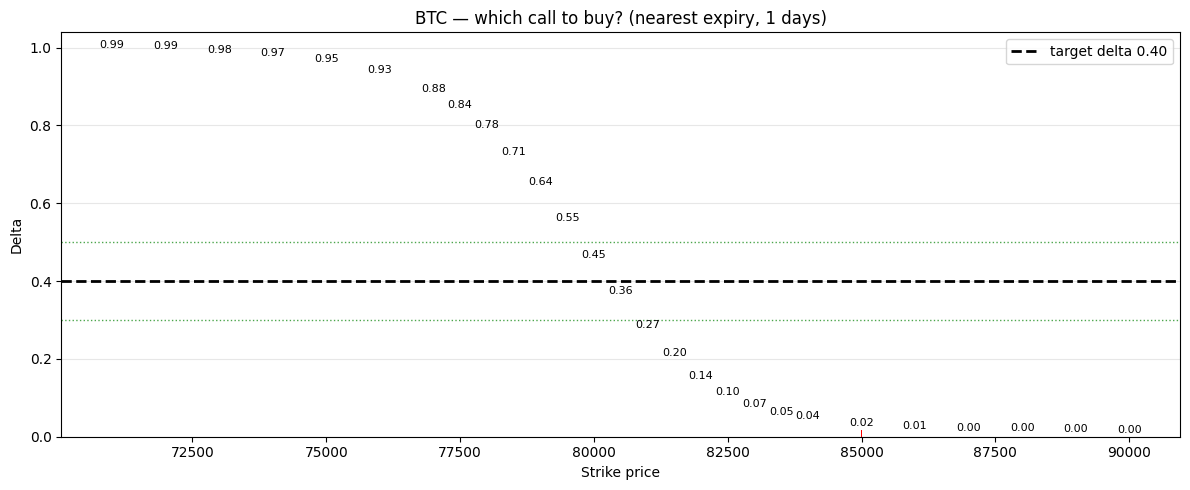


BTC - best calls to buy (delta 0.35-0.50):
  $80,000 C  delta=0.45  mark=$0.01  IV=35.5%
  $80,500 C  delta=0.36  mark=$0.01  IV=34.9%


In [74]:
import matplotlib.pyplot as plt

for cur in UNDERLYINGS:
    sub = ek[(ek.underlying == cur) & (ek.kind == 'C')]
    if sub.empty:
        continue

    # Only look at the nearest expiry
    nearest = sub[sub.days == sub.days.min()]
    nearest = nearest.sort_values('strike')

    fig, ax = plt.subplots(figsize=(12, 5))

    # Color each strike by how close its delta is to 0.40
    colors = []
    for d in nearest.delta:
        if 0.35 <= d <= 0.50:
            colors.append('green')    # sweet spot
        elif d > 0.50:
            colors.append('orange')   # too expensive
        else:
            colors.append('red')      # too cheap / too unlikely

    bars = ax.bar(nearest.strike, nearest.delta, color=colors)
    ax.axhline(0.40, color='black', ls='--', lw=2, label='target delta 0.40')
    ax.axhline(0.50, color='green', ls=':', lw=1, alpha=0.7)
    ax.axhline(0.30, color='green', ls=':', lw=1, alpha=0.7)

    ax.set_xlabel('Strike price')
    ax.set_ylabel('Delta')
    ax.set_title(f'{cur} — which call to buy? (nearest expiry, {int(nearest.days.iloc[0])} days)')
    ax.legend()
    ax.grid(alpha=0.3, axis='y')

    for bar, d in zip(bars, nearest.delta):
        ax.text(bar.get_x() + bar.get_width()/2, d + 0.01,
                f'{d:.2f}', ha='center', fontsize=8)

    plt.tight_layout()
    plt.show()

    # Print the best ones
    sweet = nearest[(nearest.delta >= 0.35) & (nearest.delta <= 0.50)]
    if len(sweet) > 0:
        print(f'\n{cur} - best calls to buy (delta 0.35-0.50):')
        for _, r in sweet.iterrows():
            print(f'  ${r.strike:,.0f} C  delta={r.delta:.2f}  mark=${r.mark:.2f}  IV={r.iv_dec*100:.1f}%')

## 22. IV heatmap (strike x expiry)

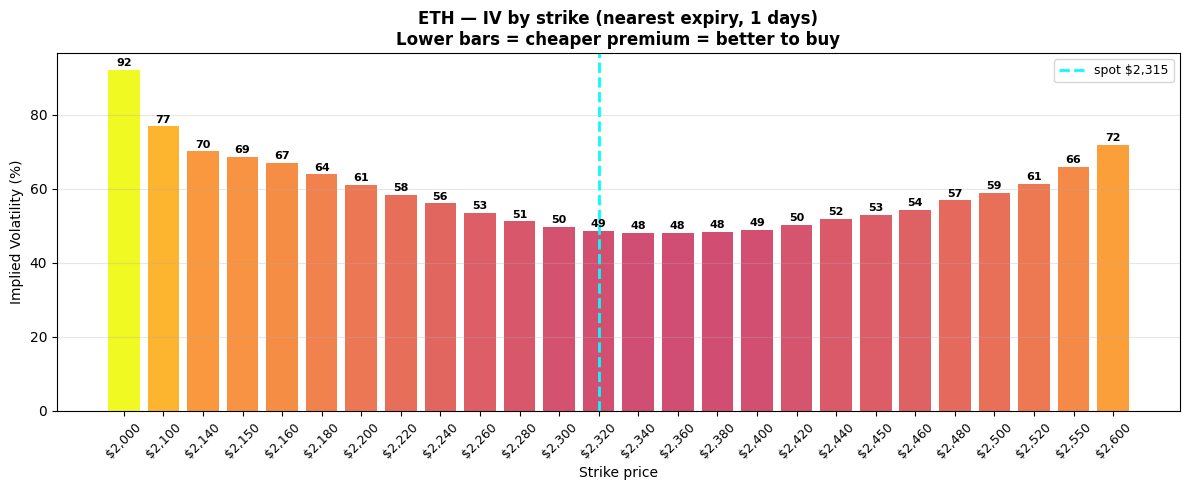

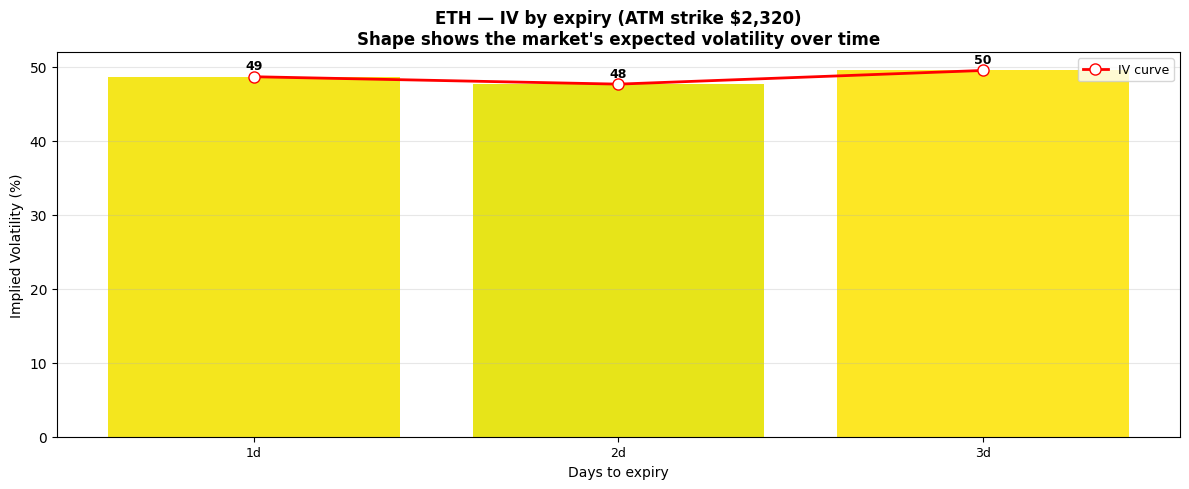


ETH term structure:
  Front IV (nearest) : 48.7%
  Back IV  (farthest): 49.5%
  Slope              : +0.9%
  -> Flat: market expects similar vol across time


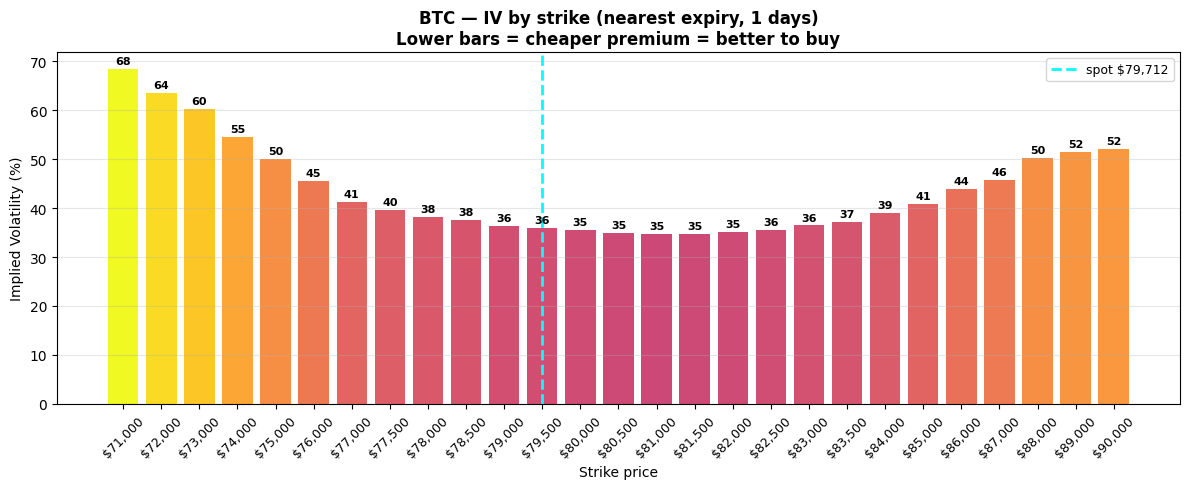

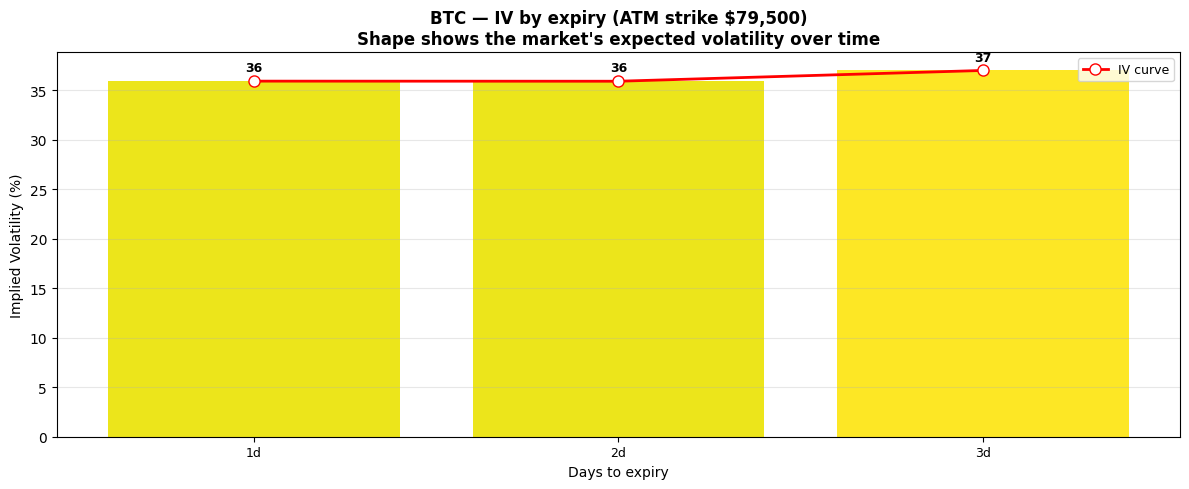


BTC term structure:
  Front IV (nearest) : 35.9%
  Back IV  (farthest): 37.0%
  Slope              : +1.1%
  -> Flat: market expects similar vol across time


In [76]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for cur in UNDERLYINGS:
    sub = ek[(ek.underlying == cur) & (ek.kind == 'C')].copy()
    if sub.empty:
        continue

    pivot = sub.pivot_table(index='strike', columns='days', values='iv_dec')
    if pivot.empty:
        continue
    pivot = pivot.sort_index()

    # Keep only near-money strikes and first 12 expiries
    if 'spots' in dir() and cur in spots:
        spot = spots[cur]
        near = pivot.index[(pivot.index > spot * 0.85) & (pivot.index < spot * 1.15)]
        pivot = pivot.loc[near] if len(near) > 0 else pivot

    pivot = pivot.iloc[:, :12]

    if pivot.empty:
        continue

    # ============================================================
    # IMAGE 1 — IV by STRIKE (nearest expiry only)
    # ============================================================
    nearest = pivot.iloc[:, 0].dropna()
    if len(nearest) > 0:
        fig, ax = plt.subplots(figsize=(12, 5))

        colors = plt.cm.plasma(nearest.values / nearest.max())

        bars = ax.bar(range(len(nearest)), nearest.values * 100, color=colors)
        ax.set_xticks(range(len(nearest)))
        ax.set_xticklabels([f'${int(s):,}' for s in nearest.index],
                           rotation=45, fontsize=9)

        ax.set_xlabel('Strike price')
        ax.set_ylabel('Implied Volatility (%)')
        ax.set_title(
            f'{cur} — IV by strike (nearest expiry, {int(pivot.columns[0])} days)\n'
            f'Lower bars = cheaper premium = better to buy',
            fontsize=12, fontweight='bold'
        )

        # Spot line
        if 'spots' in dir() and cur in spots:
            spot = spots[cur]
            nearest_idx = np.argmin(np.abs(nearest.index.values - spot))
            ax.axvline(nearest_idx, color='cyan', lw=2, ls='--',
                       label=f'spot ${spot:,.0f}')
            ax.legend(fontsize=9)

        # Annotate bars
        for bar, v in zip(bars, nearest.values):
            ax.text(bar.get_x() + bar.get_width()/2, v * 100 + 1,
                    f'{v*100:.0f}', ha='center', fontsize=8, fontweight='bold')

        ax.grid(alpha=0.3, axis='y')
        plt.tight_layout()
        plt.show()

    # ============================================================
    # IMAGE 2 — IV by EXPIRY (ATM strike only)
    # ============================================================
    if 'spots' in dir() and cur in spots:
        spot = spots[cur]
        atm_strike = pivot.index[np.argmin(np.abs(pivot.index.values - spot))]
        atm_row = pivot.loc[atm_strike].dropna()

        if len(atm_row) > 0:
            fig, ax = plt.subplots(figsize=(12, 5))

            x = range(len(atm_row))
            colors = plt.cm.viridis(atm_row.values / atm_row.max())

            bars = ax.bar(x, atm_row.values * 100, color=colors)
            ax.set_xticks(x)
            ax.set_xticklabels([f'{int(d)}d' for d in atm_row.index], fontsize=9)

            ax.set_xlabel('Days to expiry')
            ax.set_ylabel('Implied Volatility (%)')
            ax.set_title(
                f'{cur} — IV by expiry (ATM strike ${int(atm_strike):,})\n'
                f'Shape shows the market\'s expected volatility over time',
                fontsize=12, fontweight='bold'
            )

            # Annotate
            for bar, v in zip(bars, atm_row.values):
                ax.text(bar.get_x() + bar.get_width()/2, v * 100 + 1,
                        f'{v*100:.0f}', ha='center', fontsize=9, fontweight='bold')

            # Trend line
            ax.plot(x, atm_row.values * 100, color='red', lw=2, marker='o',
                    markerfacecolor='white', markeredgecolor='red',
                    markersize=8, label='IV curve')

            ax.grid(alpha=0.3, axis='y')
            ax.legend(fontsize=9)
            plt.tight_layout()
            plt.show()

            # Print interpretation
            slope = atm_row.values[-1] - atm_row.values[0]
            print(f'\n{cur} term structure:')
            print(f'  Front IV (nearest) : {atm_row.values[0]*100:.1f}%')
            print(f'  Back IV  (farthest): {atm_row.values[-1]*100:.1f}%')
            print(f'  Slope              : {slope*100:+.1f}%')
            if slope > 0.02:
                print(f'  -> Upward sloping: market expects MORE volatility later')
            elif slope < -0.02:
                print(f'  -> Inverted: market expects LESS volatility later')
            else:
                print(f'  -> Flat: market expects similar vol across time')

## 23. Bid/ask spread quality of picked contracts

In [70]:
for cur, (k, row) in picks.items():
    print(f'{cur} {k}: bid={row.bid:.2f} ask={row.ask:.2f} '
          f'mid={row.mid:.2f} spread={row.spread*100:.2f}%')
    print(f'  to exit at loss, you pay spread: ~{row.spread*100/2:.2f}% one way')

ETH P: bid=0.10 ask=0.10 mid=0.10 spread=1.00%
  to exit at loss, you pay spread: ~0.50% one way
BTC P: bid=0.03 ask=0.03 mid=0.03 spread=1.60%
  to exit at loss, you pay spread: ~0.80% one way


## 24. FINAL BUY RECOMMENDATION

In [71]:
primary = None
for cur, (k, row) in picks.items():
    if primary is None or row.score > primary[2].score:
        primary = (cur, k, row)

if primary is None:
    print('no viable candidates today - try again later')
else:
    cur, k, row = primary
    bias = direction_bias(cur)
    iv_r = iv_stats.get(cur, {}).get('rank', 50)
    pc = pcr.get(cur, {}).get('oi', 1.0)
    spot = spots[cur]
    wall = walls.get(cur, {}).get('call' if k == 'C' else 'put', row.strike)
    strike_dist = (row.strike - spot) / spot * 100

    print('=' * 70)
    print('BUY RECOMMENDATION')
    print('=' * 70)
    print(f'Underlying : {cur}')
    print(f"Direction  : {'CALL' if k == 'C' else 'PUT'}")
    print(f"Contract   : {cur}-{datetime.utcfromtimestamp(int(row.expiry)/1000):%d%b%y}-{int(row.strike)}-{k}")
    print(f'Ask        : {row.ask:.2f}')
    print(f'Expiry     : {int(row.days)} days')
    print(f'Delta      : {row.delta:.2f}   IV: {row.iv_dec*100:.1f}%')
    print(f'Gamma      : {row.gamma:.5f}   Vega: {row.vega:.4f}   Theta: {row.theta:.4f}')
    print(f'Spread     : {row.spread*100:.2f}%   OI: {row.oi:.0f}   Vol: {row.volume:.0f}')
    print()
    print('WHY:')
    print(f"  - IV rank {iv_r:.0f}/100 -> {'cheap premium' if iv_r<40 else 'neutral' if iv_r<60 else 'expensive, trim size'}")
    print(f"  - PCR(OI) {pc:.2f} -> {'fear, contrarian bullish' if pc>1.15 else 'greed, contrarian bearish' if pc<0.75 else 'balanced'}")
    print(f'  - Direction bias from data: {bias}')
    print(f'  - Strike {strike_dist:+.2f}% from spot')
    print(f'  - OI wall at {wall:.0f}')
    print()
    print('RISK:')
    print(f'  Max loss : {row.ask:.2f} (100% of premium)')
    print(f'  Stop     : {row.ask*0.5:.2f} (cut at -50%)')
    print(f'  Target   : {row.ask*2:.2f} (+100%)')
    print('=' * 70)

BUY RECOMMENDATION
Underlying : BTC
Direction  : PUT
Contract   : BTC-27Nov26-78000-P
Ask        : 0.03
Expiry     : 30 days
Delta      : -0.40   IV: 37.2%
Gamma      : 0.00004   Vega: 89.6819   Theta: -53.8256
Spread     : 1.60%   OI: 1063   Vol: 71

WHY:
  - IV rank 78/100 -> expensive, trim size
  - PCR(OI) 0.60 -> greed, contrarian bearish
  - Direction bias from data: PUT
  - Strike -2.15% from spot
  - OI wall at 60000

RISK:
  Max loss : 0.03 (100% of premium)
  Stop     : 0.02 (cut at -50%)
  Target   : 0.06 (+100%)


In [72]:
print('ALTERNATIVE (opposite direction, only if primary invalidates):')
print()
for cur, (k, row) in picks.items():
    alt_kind = 'P' if k == 'C' else 'C'
    alt = best_for(cur, alt_kind)
    if alt is None: continue
    print(f"{cur} {alt_kind}: strike={alt.strike:.0f} exp={int(alt.days)}d "
          f"IV={alt.iv_dec*100:.1f}% delta={alt.delta:.2f} ask={alt.ask:.2f}")

print()
print('=' * 70)
print('REGIME SUMMARY')
print('=' * 70)
for cur in UNDERLYINGS:
    if cur in iv_stats and cur in pcr:
        print(f"{cur}: IV_rank={iv_stats[cur]['rank']:.0f}/100  "
              f"PCR={pcr[cur]['oi']:.2f}  "
              f"skew={skew.get(cur,0)*100:+.2f}%  "
              f"call_wall={walls.get(cur,{}).get('call',0):.0f}  "
              f"put_wall={walls.get(cur,{}).get('put',0):.0f}  "
              f"max_pain={mp.get(cur,0):.0f}  "
              f"bias={direction_bias(cur)}")

ALTERNATIVE (opposite direction, only if primary invalidates):

ETH C: strike=2600 exp=58d IV=50.6% delta=0.32 ask=0.04
BTC C: strike=82000 exp=58d IV=36.7% delta=0.45 ask=0.05

REGIME SUMMARY
ETH: IV_rank=91/100  PCR=0.50  skew=+3.21%  call_wall=3200  put_wall=2300  max_pain=2320  bias=PUT
BTC: IV_rank=78/100  PCR=0.60  skew=+4.46%  call_wall=95000  put_wall=60000  max_pain=80000  bias=PUT
